# **Lab 7(A) - Laplacian Filter**
---
### Name: Mohammed Feras Sawab

### ID: 2240009066
---

In [1]:
import cv2
import numpy as np

from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)




## Apply Laplacian Filter on Image to get Sharp Image

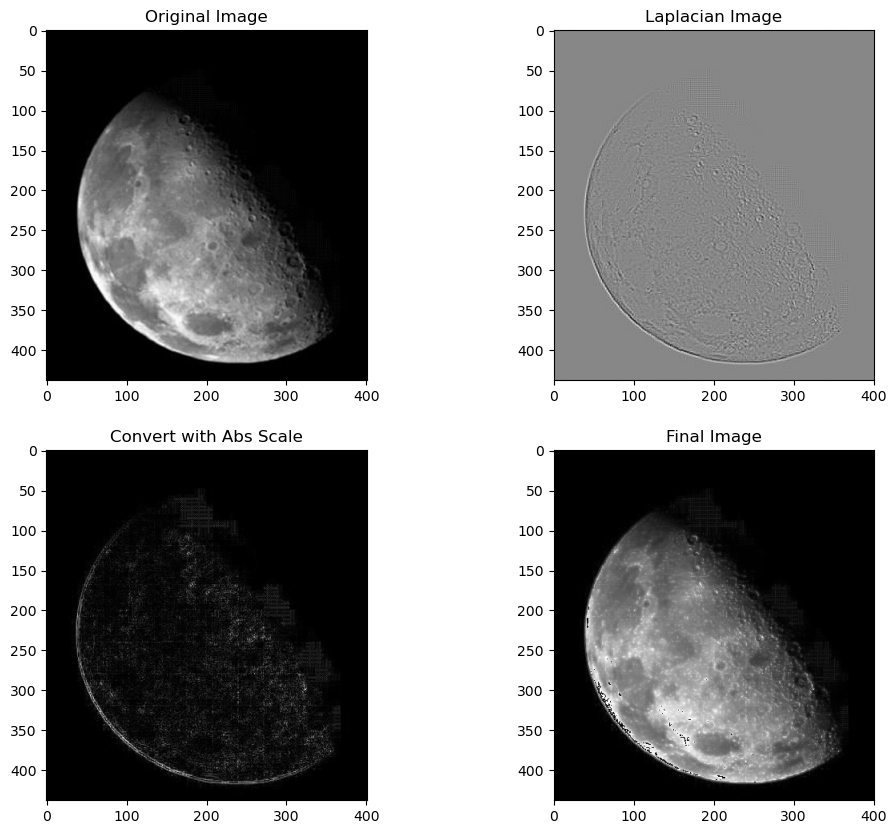

In [2]:

# ================ ( Laplacian Filter ) ===================


# 0. Image file path
imgFile = "moon.jpg"

# 1. Load image and convert to grayscale
img = cv2.imread(imgFile, 0)

# 2. Manually define the Laplacian Kernel
# This is the standard 3x3 kernel that detects horizontal and vertical edges
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# Alternative kernel: Detects diagonal edges as well
# manual_kernel = np.array([
#     [1,  1,  1],
#     [1, -8,  1],
#     [1,  1,  1]
# ], dtype=np.float32)

# 3. Apply the filter using filter2D
# -1 indicates the output image will have the same depth as the source
# However, for Laplacian, use cv2.CV_64F to avoid clipping negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Take absolute value and convert back to 8-bit (0-255)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

finalImage = img + laplacian_abs

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_abs, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage, cmap='gray'), plt.title('Final Image')
plt.show()


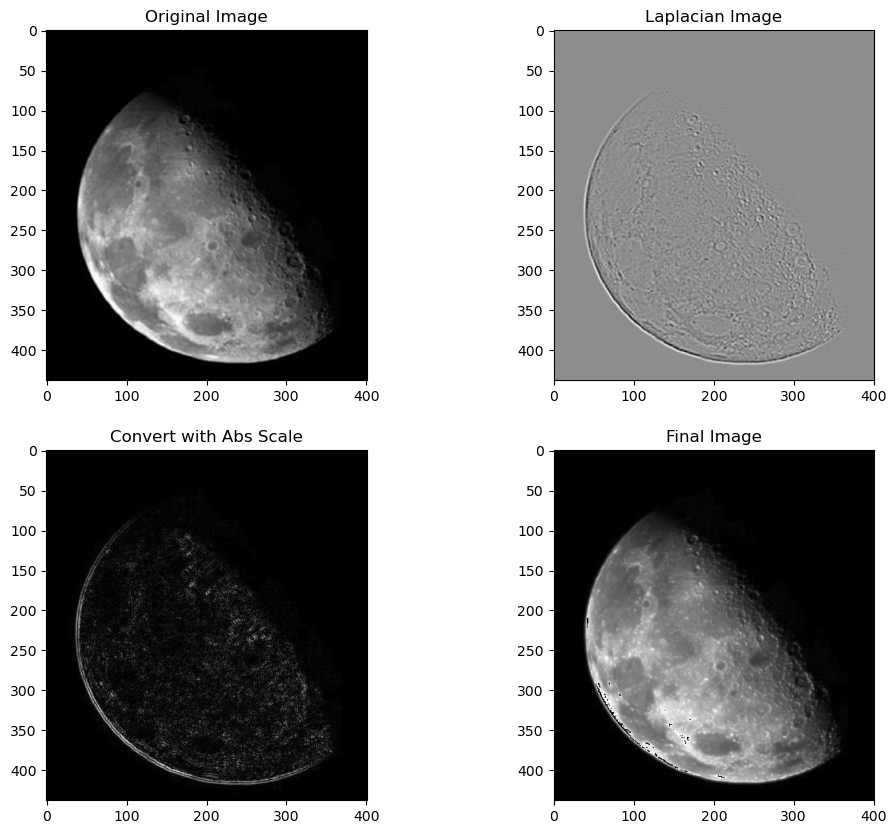

In [3]:
# ================== ( Laplacian Filter ) ===============

# 1. Optional: Apply Gaussian Blur to reduce noise
# This prevents the algorithm from picking up tiny details as edges
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. Apply the Laplacian Algorithm
# Use CV_64F to capture both positive and negative gradients (essential for edges)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F)

# 3. Convert back to 8-bit image to view it properly
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Adding Laplace and origianl Image
finalImage2 = img + laplacian_8bit

# 5. Display images
plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'), plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'), plt.title('Final Image')
plt.show()




##

# Task: Applying the Laplacian Filter on a Colored Image

A colored image has three channels (R, G, B). There are two common ways to apply the Laplacian to it:
1. Per channel: apply the kernel on each channel separately
2. Brightness only: convert to HSV, sharpen only the V (Value / brightness) channel and keep Hue and Saturation without change.

## Laplacian Filter on each Color Channel

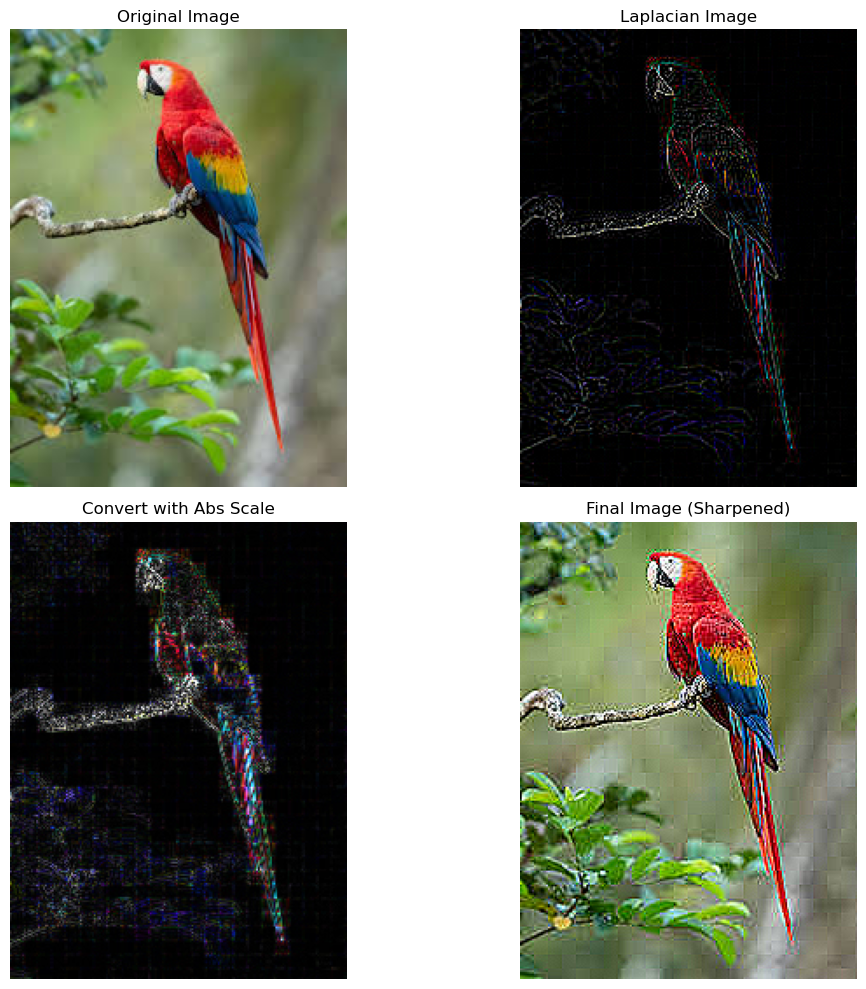

In [4]:
colorFile = "../lab5/images/images.jpeg"

img_color = cv2.cvtColor(cv2.imread(colorFile), cv2.COLOR_BGR2RGB)

lap_color = cv2.filter2D(img_color, cv2.CV_64F, manual_kernel)

lap_color_abs = cv2.convertScaleAbs(lap_color)

sharp_color = np.clip(img_color.astype(np.float64) - lap_color, 0, 255).astype(np.uint8)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img_color), plt.title('Original Image')
plt.subplot(222), plt.imshow(np.clip(lap_color, 0, 255).astype(np.uint8)), plt.title('Laplacian Image')
plt.subplot(223), plt.imshow(lap_color_abs), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(sharp_color), plt.title('Final Image (Sharpened)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()


## Laplacian Filter on the Brightness Channel only (HSV)

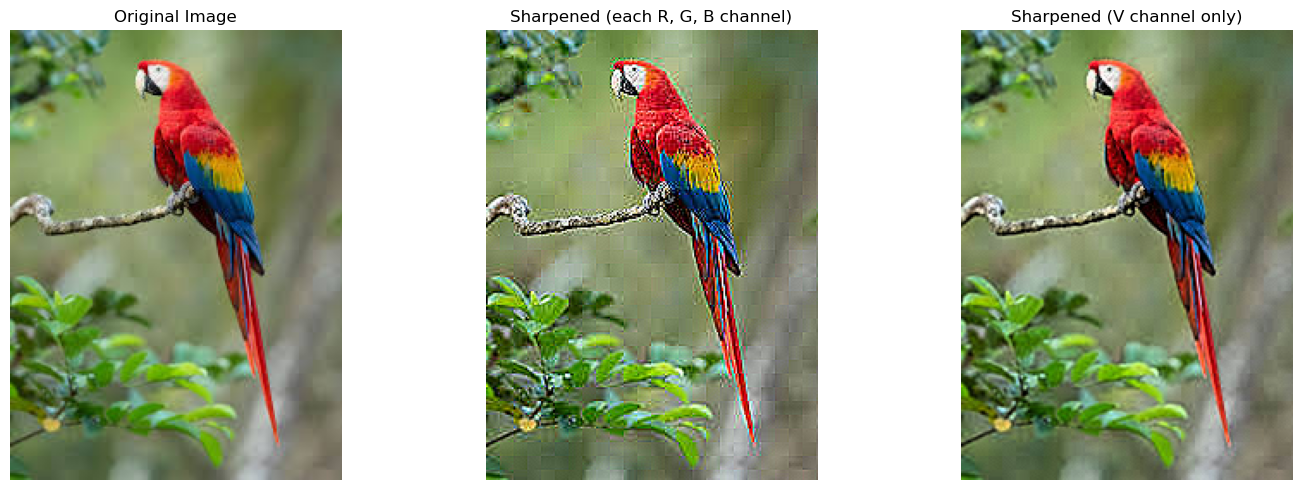

In [5]:
hsv = cv2.cvtColor(img_color, cv2.COLOR_RGB2HSV)
h, s, v = cv2.split(hsv)

v_blurred = cv2.GaussianBlur(v, (3, 3), 0)
lap_v = cv2.Laplacian(v_blurred, cv2.CV_64F)

v_sharp = np.clip(v.astype(np.float64) - lap_v, 0, 255).astype(np.uint8)

sharp_hsv = cv2.cvtColor(cv2.merge([h, s, v_sharp]), cv2.COLOR_HSV2RGB)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img_color), plt.title('Original Image')
plt.subplot(132), plt.imshow(sharp_color), plt.title('Sharpened (each R, G, B channel)')
plt.subplot(133), plt.imshow(sharp_hsv), plt.title('Sharpened (V channel only)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

## Laplacian Filter on a Noisy Colored Image

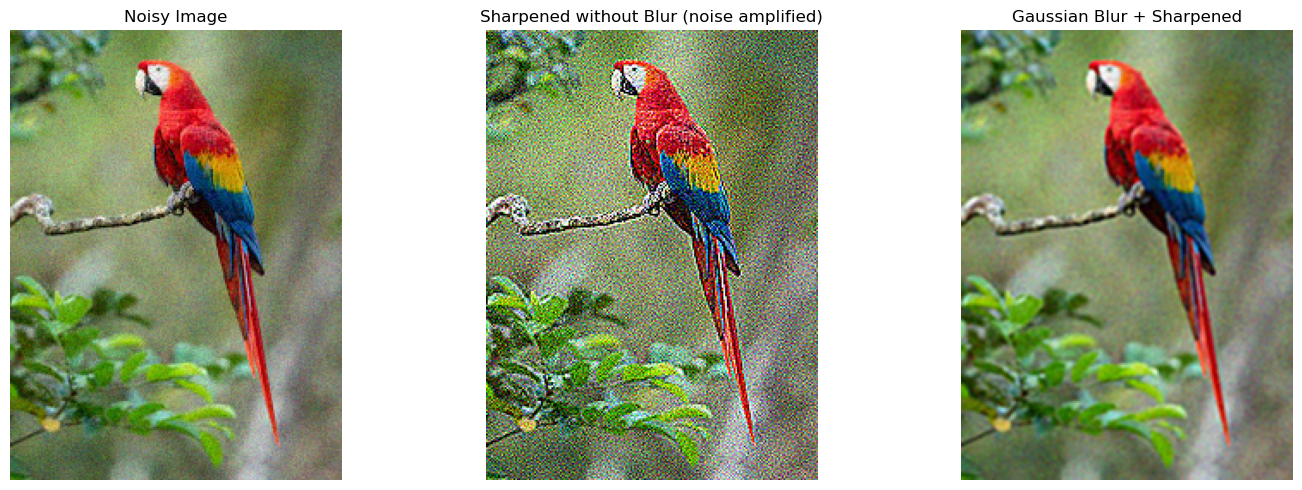

In [6]:
np.random.seed(0)
gauss = np.random.normal(0, 10, img_color.shape)
noisy_color = np.clip(img_color + gauss, 0, 255).astype(np.uint8)

lap_noisy = cv2.Laplacian(noisy_color, cv2.CV_64F)
sharp_noisy = np.clip(noisy_color.astype(np.float64) - lap_noisy, 0, 255).astype(np.uint8)

noisy_blurred = cv2.GaussianBlur(noisy_color, (5, 5), 0)
lap_blurred = cv2.Laplacian(noisy_blurred, cv2.CV_64F)
sharp_fixed = np.clip(noisy_blurred.astype(np.float64) - lap_blurred, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(noisy_color), plt.title('Noisy Image')
plt.subplot(132), plt.imshow(sharp_noisy), plt.title('Sharpened without Blur (noise amplified)')
plt.subplot(133), plt.imshow(sharp_fixed), plt.title('Gaussian Blur + Sharpened')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()
